# Soul mates with Bayes, on real contact diaries

Two surveys asked people to write down everyone they met on a day. POLYMOD covers 8 European countries
in 2005 and 2006 (Mossong et al. 2008, Zenodo record 3874557, licence CC BY-NC 4.0). The French survey
of 2012 adds a ninth country (Béraud et al. 2015, Zenodo record 3886590, licence CC BY-NC-ND 4.0).
A contact counts when two people touch skin to skin, or talk face to face for at least three words. For
each contact, people said how often they usually meet that person, and a contact marked "first time" is
a new person.

Your soul mate is drawn from the people within 5 years of your age. So this notebook counts only new
people within 5 years of the participant's age. Strangers you only glance at are not counted.

Run these once before this notebook: `uv run python scripts/download_polymod.py`,
`uv run python scripts/download_france.py` and `uv run python scripts/download_wpp.py`.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from soulmates.france import load_diaries
from soulmates.model import age_band, build_model, p_find, recog_prior
from soulmates.wpp import POLYMOD_COUNTRIES, pool_size

df = load_diaries("../data/raw")
adults = df[df["age"].between(18, 60)]
adults.groupby("country")["new_contacts"].agg(diaries="size", new_people_per_day="mean").round(2)

no part_age: 65 of 7290 rows (0.9%)
no dayofweek: 136 of 7290 rows (1.9%)
no frequency_multi: 1407 of 97904 rows (1.4%)


,diaries,new_people_per_day
country,,
BE,405,0.35
DE,716,0.10
FI,522,0.41
FR,1343,0.41
GB,517,0.29
IT,458,0.47
LU,519,0.44
NL,104,0.48
PL,545,0.33


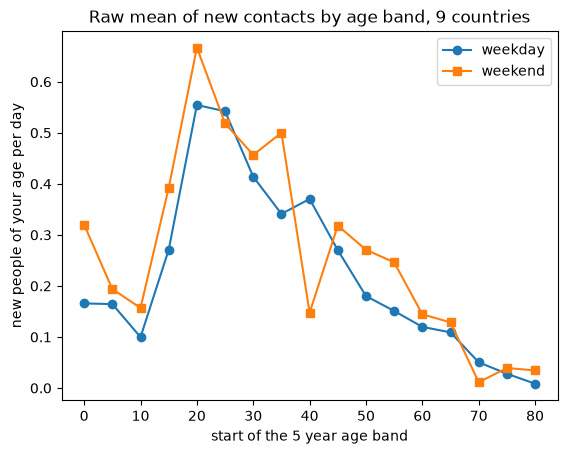

In [2]:
raw = df.groupby([age_band(df["age"]), "weekend"])["new_contacts"].mean().unstack()
fig, ax = plt.subplots()
ax.plot(raw.index * 5, raw[False], "o-", label="weekday")
ax.plot(raw.index * 5, raw[True], "s-", label="weekend")
ax.set(xlabel="start of the 5 year age band", ylabel="new people of your age per day",
       title="Raw mean of new contacts by age band, 9 countries")
ax.legend();

## Fit

The model has a level for each age band and a factor for each country. The factors come from one shared
distribution, so the model also says how far a country we have no data for could sit from the average.
A weekend day has exp(beta_weekend) times the new contacts of a weekday.

In [3]:
# The speaker's guess: "I am 90% sure that p_recog lies between 0.3 and 0.9"
RECOG_BOUNDS = (0.3, 0.9)
RECOG_MASS = 0.9

model = build_model(df, recog_bounds=RECOG_BOUNDS, recog_mass=RECOG_MASS)
with model:
    idata = pm.sample(random_seed=2)
print("divergences", int(idata.sample_stats["diverging"].sum()))
az.summary(idata, var_names=["mu_pop", "sigma_band", "sigma_country", "alpha", "beta_weekend", "p_recog"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, sigma_country, log_factor, beta_weekend, alpha, z_new, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 48 seconds.


divergences 0


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_pop,-1.8,0.218,-2.1,-1.4,713,1091,1.01,0.0081,0.0047
sigma_band,0.874,0.159,0.65,1.2,1027,1567,1.00,0.0049,0.0032
sigma_country,0.537,0.143,0.35,0.78,3978,2739,1.00,0.0023,0.0031
alpha,0.151,0.0071,0.14,0.16,4497,3319,1.00,0.00011,0.00012
beta_weekend,0.208,0.075,0.089,0.32,4593,3271,1.00,0.0011,0.0011
p_recog,0.596,0.183,0.28,0.87,4202,2707,1.00,0.0028,0.0025


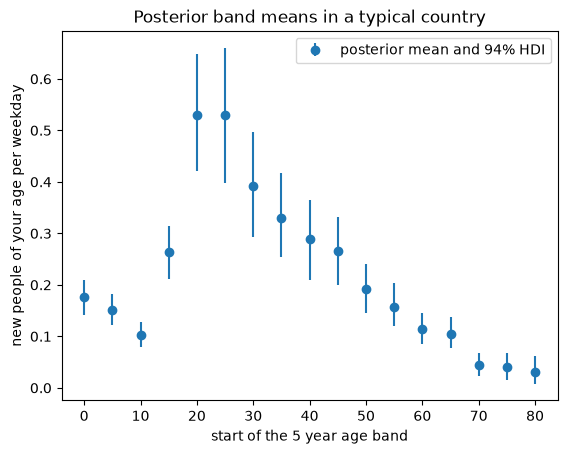

In [4]:
hdi = az.hdi(idata, var_names=["band_mean"], prob=0.94)["band_mean"].values
mean = idata.posterior["band_mean"].mean(("chain", "draw")).values
ages = np.arange(17) * 5
fig, ax = plt.subplots()
ax.errorbar(ages, mean, yerr=[mean - hdi[:, 0], hdi[:, 1] - mean], fmt="o", label="posterior mean and 94% HDI")
ax.set(xlabel="start of the 5 year age band", ylabel="new people of your age per weekday",
       title="Posterior band means in a typical country")
ax.legend();

## The guess behind p_recog

p_recog is the chance that you both realize it at some point after you have met and talked. No data
informs it. The guess "I am 90% sure it lies between 0.3 and 0.9" becomes a Beta prior through PreliZ
`maxent`, which picks the flattest Beta curve that puts 90% between the two bounds. The posterior of
p_recog equals its prior, so the draws below show the prior.

Beta(3.61, 2.47), mean 0.596, share between the bounds 0.905


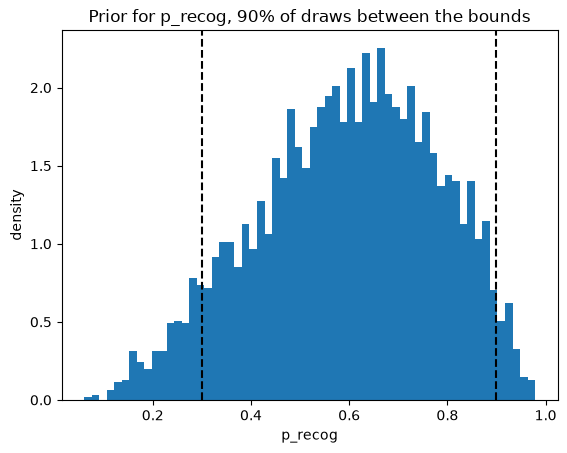

In [5]:
p_recog = idata.posterior["p_recog"].values.ravel()
inside = ((p_recog > RECOG_BOUNDS[0]) & (p_recog < RECOG_BOUNDS[1])).mean()
fig, ax = plt.subplots()
ax.hist(p_recog, bins=60, density=True)
for bound in RECOG_BOUNDS:
    ax.axvline(bound, color="k", linestyle="--")
ax.set(xlabel="p_recog", ylabel="density", title=f"Prior for p_recog, {inside:.0%} of draws between the bounds")
a, b = recog_prior(RECOG_BOUNDS, RECOG_MASS)
print(f"Beta({a:.2f}, {b:.2f}), mean {p_recog.mean():.3f}, share between the bounds {inside:.3f}")

## The odds, country by country

P_find = 1 − (1 − p_recog / M) ^ lifetime. M is everyone alive in 2023 aged 25 to 35, from the UN World
Population Prospects 2024 (licence CC BY 3.0 IGO). Your soul mate can live anywhere, so every country
uses the world pool. The lifetime count is the number of new people of your age you talk to between
15 and 60.

In [6]:
wpp = pd.read_csv("../data/wpp_pool.csv")  # written by scripts/download_wpp.py
M = pool_size(wpp)
NAMES = {"BE": "Belgium", "DE": "Germany", "FI": "Finland", "FR": "France", "GB": "Great Britain",
         "IT": "Italy", "LU": "Luxembourg", "NL": "Netherlands", "PL": "Poland"}


def row(label, life, pf):
    return {"where you live": label, "new people, 15 to 60": round(life.mean()),
            "from": round(np.percentile(life, 3)), "to": round(np.percentile(life, 97)),
            "odds: 1 in": round(1 / pf.mean())}


life_c, pf_c = idata.posterior["lifetime_country"], p_find(idata, M, lifetime="lifetime_country")
rows = [row(NAMES[c], life_c.sel(country=c).values.ravel(), pf_c.sel(country=c).values.ravel())
        for c in life_c["country"].values]
table = pd.DataFrame(rows).sort_values("odds: 1 in").reset_index(drop=True)
table

,where you live,"new people, 15 to 60",from,to,odds: 1 in
0,Italy,9617,7775,11827,231870
1,Netherlands,8778,6047,12488,253298
2,Finland,6767,5503,8265,329538
3,France,6642,5805,7551,335817
4,Luxembourg,6623,5433,8065,336467
5,Belgium,6337,5028,7955,351985
6,Poland,5318,4323,6493,419667
7,Great Britain,5105,4107,6250,436966
8,Germany,1777,1363,2266,1255282


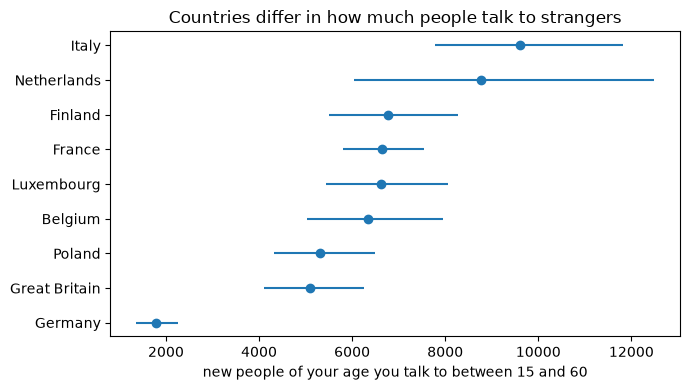

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(table))[::-1]
ax.errorbar(table["new people, 15 to 60"], y, xerr=[table["new people, 15 to 60"] - table["from"],
            table["to"] - table["new people, 15 to 60"]], fmt="o")
ax.set_yticks(y, table["where you live"])
ax.set(xlabel="new people of your age you talk to between 15 and 60", title="Countries differ in how much people talk to strangers")
fig.tight_layout()

## The headline

For a person in a country we have no data for, the model draws a new country from the distribution the
9 countries came from. That count carries the spread between countries.

lifetime_anywhere: median 5,817, 94% interval 2,003 to 16,976
lifetime_typical: median 5,778, 94% interval 5,247 to 6,362
world: M = 1,328,956,521, P_find mean 3.07e-06 (1 in 325,806), 94% interval 1 in 1,526,676 to 1 in 114,995
8 POLYMOD countries: M = 39,411,641, P_find mean 1.03e-04 (1 in 9,663), 94% interval 1 in 45,276 to 1 in 3,411
people of your generation who find their one soul mate: about 4,079 of 1,328,956,521


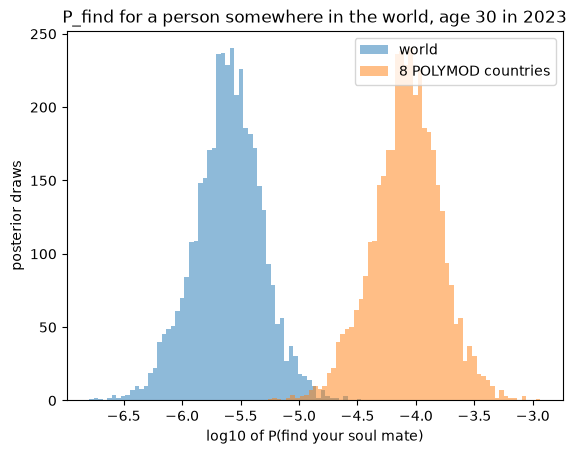

In [8]:
pools = {"world": M, "8 POLYMOD countries": pool_size(wpp, locations=POLYMOD_COUNTRIES)}
for label in ("lifetime_anywhere", "lifetime_typical"):
    life = idata.posterior[label].values.ravel()
    print(f"{label}: median {np.median(life):,.0f}, 94% interval {np.percentile(life, 3):,.0f} to {np.percentile(life, 97):,.0f}")
fig, ax = plt.subplots()
for label, m in pools.items():
    pf = p_find(idata, m).values.ravel()
    print(f"{label}: M = {m:,.0f}, P_find mean {pf.mean():.2e} (1 in {1 / pf.mean():,.0f}), "
          f"94% interval 1 in {1 / np.percentile(pf, 3):,.0f} to 1 in {1 / np.percentile(pf, 97):,.0f}")
    ax.hist(np.log10(pf), bins=60, alpha=0.5, label=label)
ax.set(xlabel="log10 of P(find your soul mate)", ylabel="posterior draws",
       title="P_find for a person somewhere in the world, age 30 in 2023")
ax.legend()
headline = p_find(idata, M).values.mean()
print(f"people of your generation who find their one soul mate: about {M * headline:,.0f} of {M:,.0f}")

## The best case

This is a best case and is labelled as one. It takes the most talkative country, first with the guess
for p_recog and then with certain recognition.

In [9]:
best = life_c.mean(("chain", "draw")).idxmax().item()
life_best = life_c.sel(country=best).values.ravel()
print(f"most talkative country: {NAMES[best]}, {life_best.mean():,.0f} new people of your age between 15 and 60")
print(f"with the guess for p_recog: 1 in {1 / pf_c.sel(country=best).values.mean():,.0f}")
print(f"if recognition were certain: 1 in {M / life_best.mean():,.0f}")

most talkative country: Italy, 9,617 new people of your age between 15 and 60
with the guess for p_recog: 1 in 231,870
if recognition were certain: 1 in 138,194


## Known limits

1. The model cannot tell culture from survey method. Four countries, Germany among them, asked for an
   estimate of professional contacts instead of a list. Germany's low level may come from that.
2. The diaries are from 2005 to 2012. They cannot see people who meet online.
3. The French participants kept a diary on two or more days. The model treats those days as separate
   diaries, which makes the French estimate a little too sure of itself.
4. The pool counts everyone and ignores gender and orientation.
5. M is a fixed number from the WPP estimates, without uncertainty.
6. Strangers you only glance at are not counted. The premise is people you meet and talk to.
7. p_recog is a guess. It drives most of the spread of the odds within one country.